In [1]:
import pandas as pd
import scipy.stats as stats
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import ttest_ind

# Loading and displaying data

In [2]:
df = pd.read_csv('ids.csv', index_col=0) #Load Dataset


FileNotFoundError: [Errno 2] No such file or directory: 'ids.csv'

In [ ]:
df.tail(50) # Display last 50 records 

# Info of columns

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 488115 entries, 0 to 488114
Data columns (total 79 columns):
 #   Column                       Non-Null Count   Dtype  
---  ------                       --------------   -----  
 0   Destination Port             488115 non-null  int64  
 1   Flow Duration                488115 non-null  int64  
 2   Total Fwd Packets            488115 non-null  int64  
 3   Total Backward Packets       488115 non-null  int64  
 4   Total Length of Fwd Packets  488115 non-null  int64  
 5   Total Length of Bwd Packets  488115 non-null  int64  
 6   Fwd Packet Length Max        488115 non-null  int64  
 7   Fwd Packet Length Min        488115 non-null  int64  
 8   Fwd Packet Length Mean       488115 non-null  float64
 9   Fwd Packet Length Std        488115 non-null  float64
 10  Bwd Packet Length Max        488115 non-null  int64  
 11  Bwd Packet Length Min        488115 non-null  int64  
 12  Bwd Packet Length Mean       488115 non-null  float64
 13  Bwd 

# Creating a new data frame with listed columns

In [6]:
columns = ['Destination Port', 'Flow Duration', 'Total Fwd Packets',
           'Total Backward Packets', 'Total Length of Fwd Packets',
           'Total Length of Bwd Packets', 'Fwd Packet Length Mean',
           'Bwd Packet Length Mean', 'Flow Bytes/s', 'Flow Packets/s',
           'Packet Length Mean', 'Packet Length Std', 'Average Packet Size',
           'Active Mean', 'Idle Mean', 'Label'] # List of required Columns
new_df = df[columns] # Create a new Dataframe with Selected Columns
new_df.head() # Display First 5 records

,Destination Port,Flow Duration,Total Fwd Packets,Total Backward Packets,Total Length of Fwd Packets,Total Length of Bwd Packets,Fwd Packet Length Mean,Bwd Packet Length Mean,Flow Bytes/s,Flow Packets/s,Packet Length Mean,Packet Length Std,Average Packet Size,Active Mean,Idle Mean,Label
0,53,62171,2,2,78,164,39.00,82.000000,3.892490e+03,64.338679,56.200000,23.552070,70.250000,0.00000,0.0,BENIGN
1,2710,48,2,0,4,0,2.00,0.000000,8.333333e+04,41666.666670,2.000000,0.000000,3.000000,0.00000,0.0,Infiltration
2,443,4792909,5,1,135,46,27.00,46.000000,3.776412e+01,1.251849,32.428571,18.866700,37.833333,0.00000,0.0,BENIGN
3,80,115596470,75,82,342,118155,4.56,1440.914634,1.025092e+03,1.358173,749.981013,946.124811,754.757962,22092.63636,10000000.0,BENIGN
4,2910,14,2,2,4,12,2.00,6.000000,1.142857e+06,285714.285700,3.600000,2.190890,4.500000,0.00000,0.0,BENIGN


# Column Info of New Dataframe

In [7]:
new_df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 488115 entries, 0 to 488114
Data columns (total 16 columns):
 #   Column                       Non-Null Count   Dtype  
---  ------                       --------------   -----  
 0   Destination Port             488115 non-null  int64  
 1   Flow Duration                488115 non-null  int64  
 2   Total Fwd Packets            488115 non-null  int64  
 3   Total Backward Packets       488115 non-null  int64  
 4   Total Length of Fwd Packets  488115 non-null  int64  
 5   Total Length of Bwd Packets  488115 non-null  int64  
 6   Fwd Packet Length Mean       488115 non-null  float64
 7   Bwd Packet Length Mean       488115 non-null  float64
 8   Flow Bytes/s                 488079 non-null  float64
 9   Flow Packets/s               488115 non-null  float64
 10  Packet Length Mean           488115 non-null  float64
 11  Packet Length Std            488115 non-null  float64
 12  Average Packet Size          488115 non-null  float64
 13  Acti

# Checking and removing missing values

In [8]:
new_df.isna().sum() # Checking for Null Values

Destination Port                0
Flow Duration                   0
Total Fwd Packets               0
Total Backward Packets          0
Total Length of Fwd Packets     0
Total Length of Bwd Packets     0
Fwd Packet Length Mean          0
Bwd Packet Length Mean          0
Flow Bytes/s                   36
Flow Packets/s                  0
Packet Length Mean              0
Packet Length Std               0
Average Packet Size             0
Active Mean                     0
Idle Mean                       0
Label                           0
dtype: int64

In [9]:
new_df = new_df.dropna() # Remove rows with Null Values

In [10]:
new_df.isna().sum() # Rechecking after removing

Destination Port               0
Flow Duration                  0
Total Fwd Packets              0
Total Backward Packets         0
Total Length of Fwd Packets    0
Total Length of Bwd Packets    0
Fwd Packet Length Mean         0
Bwd Packet Length Mean         0
Flow Bytes/s                   0
Flow Packets/s                 0
Packet Length Mean             0
Packet Length Std              0
Average Packet Size            0
Active Mean                    0
Idle Mean                      0
Label                          0
dtype: int64

# Checking duplicated records

In [11]:
new_df.duplicated().sum() # Check if Duplicate records exist

np.int64(139389)

# Displaying name of all columns

In [12]:
len(new_df.columns) # Display total number of Columns

16

In [13]:
new_df.columns # Display name of all Columns

Index(['Destination Port', 'Flow Duration', 'Total Fwd Packets',
       'Total Backward Packets', 'Total Length of Fwd Packets',
       'Total Length of Bwd Packets', 'Fwd Packet Length Mean',
       'Bwd Packet Length Mean', 'Flow Bytes/s', 'Flow Packets/s',
       'Packet Length Mean', 'Packet Length Std', 'Average Packet Size',
       'Active Mean', 'Idle Mean', 'Label'],
      dtype='object')

# Renaming the values

In [14]:
new_df['Label'].value_counts() # Display original Label Distribution

Label
BENIGN          288548
Infiltration    199531
Name: count, dtype: int64

In [15]:
new_df['Label'] = new_df['Label'].replace({ # Rename Label Values
    'BENIGN': 'Normal Traffic',
    'Infiltration': 'Attack'
})
new_df['Label'].value_counts() # Display updated Label Distribution

Label
Normal Traffic    288548
Attack            199531
Name: count, dtype: int64

# Showing summary statistics

In [16]:
columns1 = ['Total Fwd Packets', 'Total Backward Packets'] # Columns to analyze

In [17]:
for col in columns1: # Loop to calculate basic statistics
    print("\n", col, "") 
    print("Sum:", df[col].sum()) 
    print("Mean:", df[col].mean())
    print("Standard Deviation:", df[col].std()) 
    print("Skewness:", stats.skew(df[col]))
    print("Kurtosis:", stats.kurtosis(df[col]))


 Total Fwd Packets 
Sum: 3029696
Mean: 6.206930743779642
Standard Deviation: 69.85269062816748
Skewness: 137.04269372657225
Kurtosis: 30408.018375304313

 Total Backward Packets 
Sum: 3019274
Mean: 6.1855792180121485
Standard Deviation: 99.35912082347987
Skewness: 227.4740316100872
Kurtosis: 87218.69394568843


# Correlation of all numeric values

In [18]:
new_df1 = new_df.select_dtypes(include = 'number') # Selects only numeric columns
new_df1.corr()

,Destination Port,Flow Duration,Total Fwd Packets,Total Backward Packets,Total Length of Fwd Packets,Total Length of Bwd Packets,Fwd Packet Length Mean,Bwd Packet Length Mean,Flow Bytes/s,Flow Packets/s,Packet Length Mean,Packet Length Std,Average Packet Size,Active Mean,Idle Mean
Destination Port,1.000000,-0.145250,-0.025711,-0.024028,0.004815,-0.015581,0.005199,-0.217264,0.063783,0.214177,-0.118523,-0.156795,-0.127719,-0.051505,-0.109348
Flow Duration,-0.145250,1.000000,0.124344,0.100836,0.032044,0.063465,0.114950,0.351037,-0.018884,-0.113359,0.324827,0.465984,0.303080,0.204673,0.653138
Total Fwd Packets,-0.025711,0.124344,1.000000,0.949848,0.333574,0.920007,0.035838,0.210119,-0.002078,-0.020480,0.200438,0.174919,0.190185,0.137132,0.074589
Total Backward Packets,-0.024028,0.100836,0.949848,1.000000,0.146728,0.961480,0.015679,0.200844,-0.002868,-0.020564,0.186629,0.156695,0.177268,0.101969,0.066117
Total Length of Fwd Packets,0.004815,0.032044,0.333574,0.146728,1.000000,0.013944,0.127556,0.016333,0.001838,-0.006509,0.080155,0.054492,0.077949,0.058811,0.013443
Total Length of Bwd Packets,-0.015581,0.063465,0.920007,0.961480,0.013944,1.000000,-0.001047,0.194512,-0.001385,-0.012061,0.176026,0.138066,0.167419,0.078208,0.048474
Fwd Packet Length Mean,0.005199,0.114950,0.035838,0.015679,0.127556,-0.001047,1.000000,0.123866,0.154969,-0.078665,0.612858,0.462664,0.628276,0.068762,0.074170
Bwd Packet Length Mean,-0.217264,0.351037,0.210119,0.200844,0.016333,0.194512,0.123866,1.000000,-0.024280,-0.166846,0.824952,0.876817,0.809420,0.187768,0.236769
Flow Bytes/s,0.063783,-0.018884,-0.002078,-0.002868,0.001838,-0.001385,0.154969,-0.024280,1.000000,0.200319,0.127875,0.069086,0.188463,-0.006707,-0.014174
Flow Packets/s,0.214177,-0.113359,-0.020480,-0.020564,-0.006509,-0.012061,-0.078665,-0.166846,0.200319,1.000000,-0.134655,-0.145674,-0.135588,-0.040319,-0.085080


<Axes: >

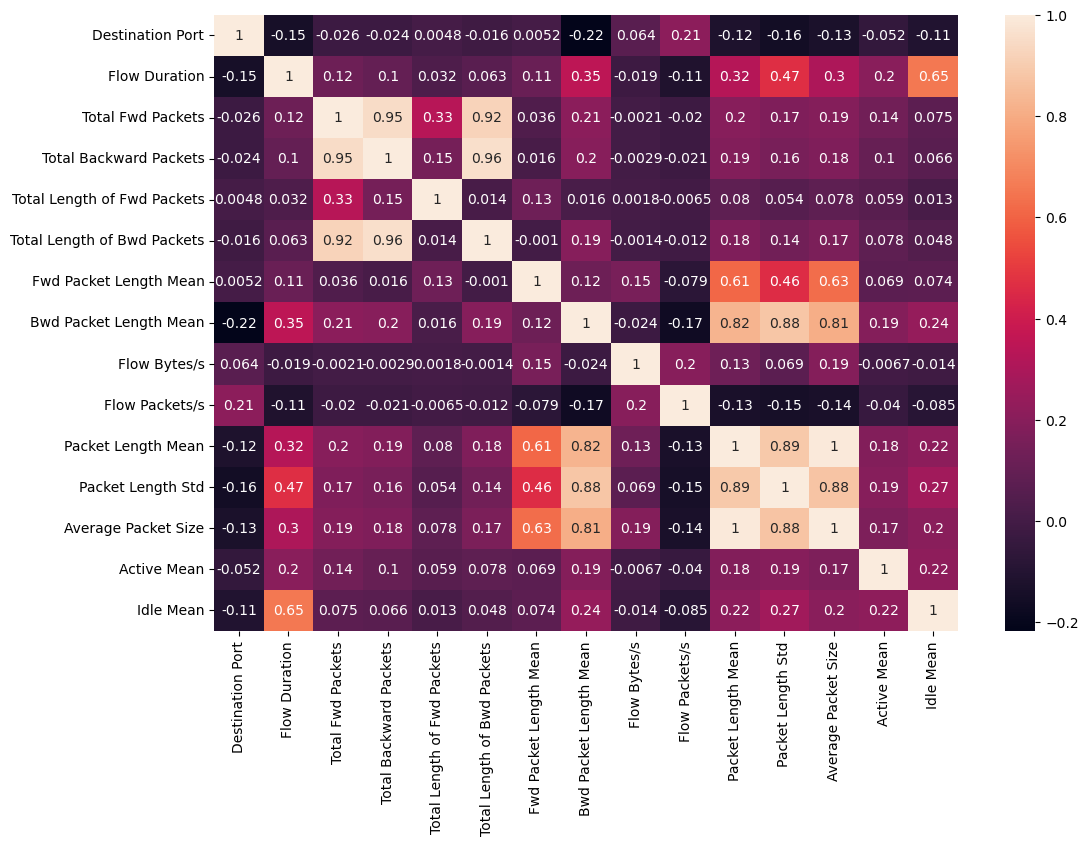

In [19]:
plt.figure(figsize=(12,8))
sns.heatmap(new_df1.corr(), annot = True) #Show correlation values

# Top 5 correlated feature

In [20]:
new_df1 = new_df.select_dtypes(include='number')

corr_matrix = new_df1.corr() # Find correlation matrix

corr_pairs = corr_matrix.unstack() #Converts matrix to pairs

corr_pairs = corr_pairs[corr_pairs != 1] # Remove same variable correlation(value = 1)

corr_pairs = corr_pairs.drop_duplicates() # Remove duplicate pairs 

top_5 = corr_pairs.reindex(corr_pairs.abs().sort_values(ascending=False).index) # Sort to find highest correlation

print("Top 5 Correlated Feature Pairs:\n") # Print top 5 correlated feature
print(top_5.head(5))


Top 5 Correlated Feature Pairs:

Packet Length Mean      Average Packet Size            0.995068
Total Backward Packets  Total Length of Bwd Packets    0.961480
Total Fwd Packets       Total Backward Packets         0.949848
                        Total Length of Bwd Packets    0.920007
Packet Length Mean      Packet Length Std              0.887792
dtype: float64


# Bar chart showing frequency

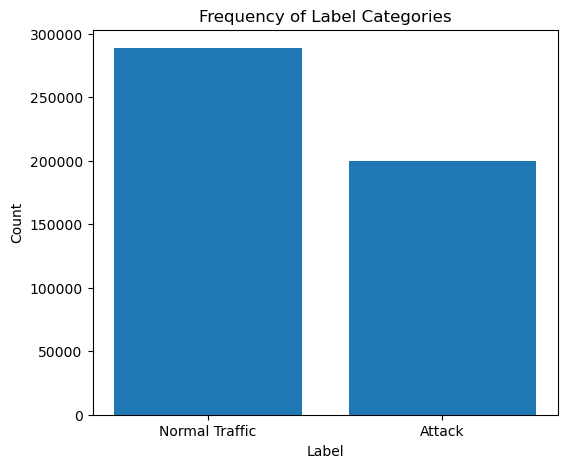

In [21]:
label_counts = new_df['Label'].value_counts() # Count number of each label

plt.figure(figsize=(6,5))
plt.bar(label_counts.index, label_counts.values) # Bar chart for level frequency

plt.title("Frequency of Label Categories")
plt.xlabel("Label")
plt.ylabel("Count")

plt.show()

# Showing the highest average in pie chart

In [22]:
group = new_df.groupby('Label')[['Flow Duration', 'Packet Length Mean']].mean() # Group data by label and find average values
group

,Flow Duration,Packet Length Mean
Label,,
Attack,8.909046e+06,85.573255
Normal Traffic,8.966348e+06,85.542480


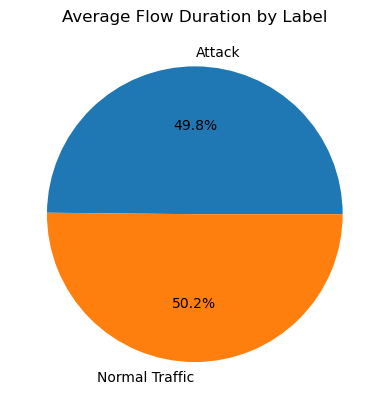

In [23]:
# Pie chart for flow duration
plt.figure()

plt.pie(
    group['Flow Duration'],
    labels=group.index,
    autopct='%1.1f%%',
)

plt.title("Average Flow Duration by Label")

plt.show()

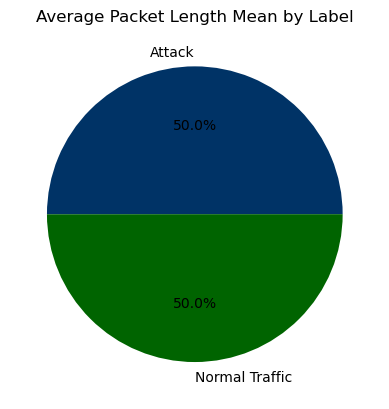

In [24]:
# Pie chart for Length Mean
colors = [
    '#003366',   
    '#006400',   
]

plt.figure()

plt.pie(
    group['Packet Length Mean'],
    labels=group.index,
    autopct='%1.1f%%',
    colors=colors
)

plt.title("Average Packet Length Mean by Label")

plt.show()

# Visualizing distribution through boxplot

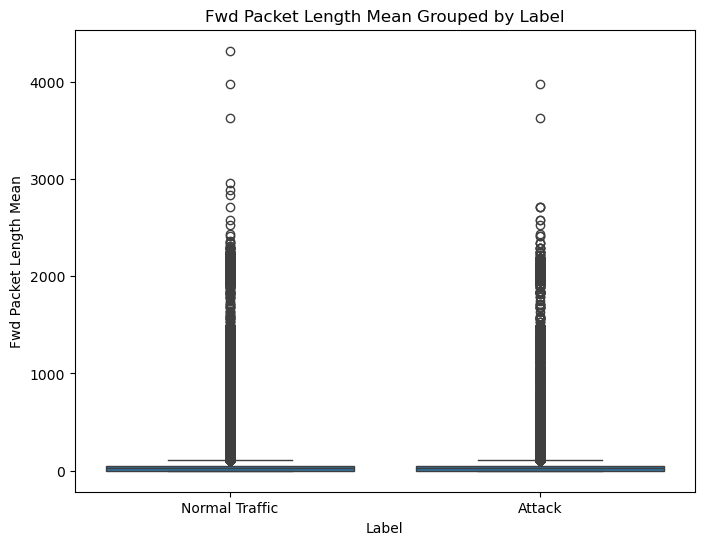

In [25]:
# Box plot to compare data distribution
plt.figure(figsize=(8,6)) 
sns.boxplot(
    x='Label',
    y='Fwd Packet Length Mean',
    data= new_df
)
plt.title("Fwd Packet Length Mean Grouped by Label")
plt.xlabel("Label")
plt.ylabel("Fwd Packet Length Mean")
plt.show()

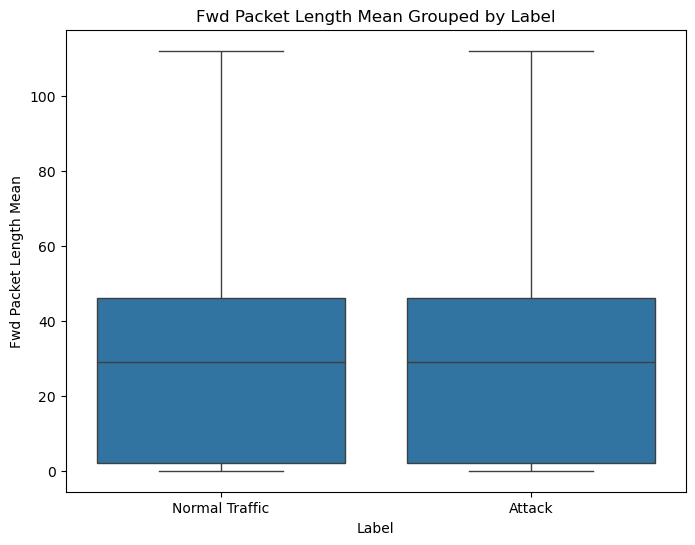

In [26]:
# Box plot without outliers
plt.figure(figsize=(8,6))

sns.boxplot(
    x='Label',
    y='Fwd Packet Length Mean',
    data=new_df,
    showfliers=False  
)

plt.title("Fwd Packet Length Mean Grouped by Label")
plt.xlabel("Label")
plt.ylabel("Fwd Packet Length Mean")

plt.show()

# Performing hypothesis test

In [27]:
# Separate normal and attack data
normal = new_df[new_df['Label'] == 'Normal Traffic']['Flow Duration']
attack = new_df[new_df['Label'] == 'Attack']['Flow Duration']

# Calculate mean
normal_mean = normal.mean()
attack_mean = attack.mean()

t_stat, p_val = ttest_ind(normal,attack) # Perform ttest

# Print result
print("Mean (Normal Traffic):", normal_mean)
print("Mean (Attack):", attack_mean)
print("P-value is:", p_val)

#Decision
if p_val < 0.05:
    print("Reject the null hypothesis")

else:
    print("Fail to reject the null hypothesis")

Mean (Normal Traffic): 8966348.484681925
Mean (Attack): 8909046.444346994
P-value is: 0.473909720385436
Fail to reject the null hypothesis
